In [ ]:
from pathlib import Path
import os
from PIL import Image
import time
import copy
import json
import datetime

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch
import random

from torchvision import transforms as T
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import Dataset
import torch.nn.functional as F
 
import torch, torch.nn as nn
from torchvision import models
from sklearn.metrics import roc_auc_score, confusion_matrix, average_precision_score, roc_curve

In [4]:
if Path('/kaggle/input').exists():
    # Trên Kaggle, thư mục repo vừa clone nằm trong /kaggle/working/Chest_XRay_Pneumonia
    project_root = Path('/kaggle/working/Chest_XRay_Pneumonia')
    base_dir = Path('/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia')
else:
    # Trên máy cá nhân (WSL), lùi 1 cấp nếu notebook đang nằm trong thư mục notebook/
    project_root = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
    base_dir = project_root / 'data/raw/chest_xray'

print("Project root:", project_root)
print("Data base dir:", base_dir)

Project root: /home/hiughetlinux/hoc-software/Chest_Xray_Pneumonia_Project
Data base dir: /home/hiughetlinux/hoc-software/Chest_Xray_Pneumonia_Project/data/raw/chest_xray


# 1. Merge 3 set into 1

*A patient may have more than 1 image. So all images of that person need to be in a same set to prevent data leakage*



In [5]:
import re
def get_patient_id(path):
    name = Path(path).name
    m = re.match(pattern = r'person(\d+)_', string=name)
    if m:
        return f'P{m.group(1)}'
    m = re.search(pattern = r'IM-(\d+)-', string= name)
    if m:
        return f'N{m.group(1)}'
    return f'U_{name}'

valid_exts =['.jpeg', '.png', '.jpg']
records = []
corrupted_files = []

for split in ['train','val', 'test']:
    split_dir = base_dir / split
    if not split_dir.exists():
        continue

    for class_dir in split_dir.iterdir():
        if not class_dir.exists():
            continue

        for img_path in class_dir.iterdir():
            if img_path.suffix.lower() not in valid_exts:
                continue

            try:
                with Image.open(img_path) as img:
                    id = get_patient_id(img_path)
                    width, height = img.size
                    mode = img.mode  # 'L' là ảnh xám 1 kênh, 'RGB' là ảnh màu 3 kênh
                    records.append({
                        'patient_id': id,
                        "split": split,
                        "label": class_dir.name,
                        "width": width,
                        "height": height,
                        "aspect_ratio": round(width / height, 2),
                        "mode": mode,
                        "path": str(img_path)
                    })
                
            except Exception as e:
                corrupted_files.append((str(img_path), e))
df = pd.DataFrame(records)               
   

In [6]:
# Split into 3 set again


cleaned_df = df[df['split'].isin(['train','val'])]
test_df = df[df['split']=='test']
cleaned_df=cleaned_df.drop(columns='split')
test_df=test_df.drop(columns='split')

mapping_label = {'PNEUMONIA': 1, 'NORMAL': 0}
cleaned_df['label'] = cleaned_df['label'].map(mapping_label)
test_df['label'] = test_df['label'].map(mapping_label)


sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=36)
train_idx, val_idx = next(sgkf.split(cleaned_df,cleaned_df['label'],groups=cleaned_df['patient_id']))
train_df, val_df = cleaned_df.iloc[train_idx], cleaned_df.iloc[val_idx]

assert set(train_df.patient_id).isdisjoint(set(val_df.patient_id))

train_df.to_csv(project_root / 'data/data_split/train.csv', index = False)
val_df.to_csv(project_root / 'data/data_split/val.csv', index = False)
test_df.to_csv(project_root / 'data/data_split/test.csv', index = False)

# 2. Dataset, DataLoader

In [20]:
class BorderDrop:
    def __init__(self, p=0.7 , fraction = (0.15,0.3)):
        self.p = p
        self.fraction = fraction
    def __call__(self,x):
        if torch.rand(1).item()>self.p:
            return x
        else:
            h, w = x.shape[-2:]
            k = int(h*np.random.uniform(*self.fraction))
            keep = torch.zeros_like(x)
            keep[:, k:h-k, k:w-k]=1
            return x*keep

In [21]:
norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
tfm_none = T.Compose([T.Resize((224,224)),
                      T.ToTensor(),
                      norm
                      ])


tfm_shortcut = T.Compose(
    [
        T.RandomResizedCrop(size = 224, scale=(0.7,1), ratio = (0.85, 1.15)),
        T.RandomApply([T.GaussianBlur(5,sigma=(0.1,2))], p = 0.5),
        T.RandomAffine(degrees=8, translate=(0.05, 0.05)),
        T.ColorJitter(brightness=0.2, contrast=0.2),
        T.ToTensor(),
        norm,
        BorderDrop()
    ]
)

In [9]:
# Dataset

class CXRDataset(Dataset):
    def __init__(self, csv_path, transform, base_dir=None):
        self.df = pd.read_csv(csv_path)
        self.transform = transform
        self.base_dir = Path(base_dir) if base_dir else None

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        raw_path = Path(r['path'])
        
        # Nếu có truyền base_dir (ví dụ trên Kaggle), ghép lại đường dẫn từ cấp 'train/NORMAL/...'
        if self.base_dir is not None and not raw_path.exists():
            # Lấy 3 cấp cuối: split / label / filename (ví dụ: train/PNEUMONIA/person1803_bacteria_4652.jpeg)
            rel_path = Path(*raw_path.parts[-3:])
            img_path = self.base_dir / rel_path
        else:
            img_path = raw_path
            
        img = Image.open(img_path).convert('RGB')
        return self.transform(img), int(r['label'])

In [10]:
# Dataloader
val_dl = DataLoader(CXRDataset(
    csv_path=project_root / 'data/data_split/val.csv',
    transform= tfm_none,
    base_dir = base_dir
),
    batch_size=64,
    shuffle=False,
    num_workers=2
    )


# 3. Set up

In [11]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = models.resnet18(weights = models.ResNet18_Weights.DEFAULT)

#Freezing parameter for transfer learning
for p in model.parameters():
    p.requires_grad = False

#Create a Fully connected layer in the last, with 2 output feature
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(device)


#weight to compensate the imbalance (73% is Pnemonia)
counts = train_df['label'].value_counts().sort_index().values
weights = torch.tensor(len(train_df)/(2*counts), dtype = torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight = weights)
optimizer = torch.optim.Adam(params = model.fc.parameters(), lr = 1e-3)


In [12]:

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
  
        

def build_model(mode):
    pre_trained = mode != 'scratch'
    model = models.resnet18(weights = models.ResNet18_Weights.DEFAULT if pre_trained else None)
    model.fc = nn.Linear(model.fc.in_features, 2)

    if mode == 'last':
        for name, p in model.named_parameters():
            p.requires_grad = name.startswith('layer4') or name.startswith('fc')
    return model.to(device)   



def make_optimizer(model, mode, lr_head, lr_backbone, wd = 1e-4):
    if mode == 'scratch':
        return torch.optim.AdamW(model.parameters(), lr = lr_head, weight_decay = wd)

    head = list(model.fc.parameters())
    head_ids = {id(p) for p in head}

    backbone = [p for p in model.parameters() if (p.requires_grad == True and id(p) not in head_ids)]

    return torch.optim.AdamW(
        [{'params': backbone, 'lr' : lr_backbone},
        {'params': head, 'lr': lr_head}],
        weight_decay = wd
    )



def set_train_mode(model, mode):
    model.train()
    if mode == 'last':
        for layer in [model.conv1, model.bn1, model.layer1, model.layer2, model.layer3]:
            layer.eval()



def to_float(val):
    try:
        return float(val)
    except (ValueError, TypeError):
        return 0.0



def spec_at_recall(labels, probs, target_recall=0.95):
    fpr, tpr, thr = roc_curve(labels, probs)
    idx = np.where(tpr >= target_recall)[0]
    i = idx[np.argmin(fpr[idx])]          # fpr nhỏ nhất = specificity lớn nhất
    return thr[i], tpr[i], 1 - fpr[i]     # thứ tự: ngưỡng, recall, specificity







@torch.no_grad()
def get_probs_and_labels(model, dl):
    model.eval()
    probs, labels = [], []
    for x, y in dl:
        p = torch.softmax(model(x.to(device)), dim=1)[:, 1].cpu().numpy()
        probs.append(p)
        labels.append(y.numpy())
    return np.concatenate(probs), np.concatenate(labels)     

In [ ]:
def run_experiment(name, mode, epochs = 15, lr_backbone = 1e-4, lr_head=1e-3, seed =36, patient = 5):
    set_seed(seed)
    model = build_model(mode)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'{name} | mode={mode} | trainable params: {n_params:,}')

    opt = make_optimizer(model, mode, lr_head, lr_backbone)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max = epochs)

    best_auc, best_state, bad, history = 0, None, 0, []
    for epoch in range(epochs):
        t0 = time.time()
        set_train_mode(model, mode)
        total, n = 0.0, 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = criterion(model(x),y)
            loss.backward()
            opt.step()
            total+=loss.item()*x.size(0)
            n+=x.size(0)
        sched.step()

        probs, labels = get_probs_and_labels(model, val_dl)
        auc = roc_auc_score(labels, probs)
        pr = average_precision_score(labels, probs)
        thr, recall, spec = spec_at_recall(labels, probs,target_recall = 0.95)
        val_spec = to_float(spec)
        val_rec = to_float(recall)                                  

        history.append({'epoch': epoch, 'train_loss': total / n, 'val_auc': auc,
                'val_pr_auc': pr, 'spec_at_rec95': val_spec, 'recall': val_rec})
        print(f'ep{epoch:02d} train {total/n:.3f} auc {auc:.4f} pr {pr:.4f} spec@rec95 {val_spec:.3f} recall {val_rec:.3f} ({time.time()-t0:.0f}s)')

        if auc > best_auc:
            best_auc = auc
            best_state= copy.deepcopy(model.state_dict())
            bad = 0
        else:
            bad+=1
            if bad >= patient:
                print('Early stop')
                break
            
        

    # Đánh giá lại với checkpoint tốt nhất và lưu kết quả
    model.load_state_dict(best_state)
    probs, labels = get_probs_and_labels(model, val_dl)
    row = {'exp': name, 'mode': mode, 'seed': seed, 'trainable_params': n_params,
           'epochs_run': len(history), 'val_auc': roc_auc_score(labels, probs),
           'val_pr_auc': average_precision_score(labels, probs)}
    for t in [0.90, 0.95, 0.98]:
        thr, rec, spec = spec_at_recall(labels, probs, t)
        row.update({f'thr@rec{int(t*100)}': thr, f'spec@rec{int(t*100)}': spec})

    os.makedirs(project_root/'outputs/results', exist_ok=True)
    os.makedirs(project_root/'outputs/logs', exist_ok=True)
    os.makedirs(project_root/'outputs/checkpoints', exist_ok=True)
    pd.DataFrame([row]).to_csv(project_root / f'outputs/results/{name}_seed{seed}.csv', index=False)
    pd.DataFrame(history).to_csv(project_root / f'outputs/logs/{name}_seed{seed}_log.csv', index=False)
    torch.save(best_state, project_root / f'outputs/checkpoints/{name}_seed{seed}.pt')
    return row
    

# 4. Training

*In this step, you can load model parameter trained before to avoid a long time of training*

``m = build_model('last')
m.load_state_dict(torch.load(project_root/'outputs_backup/checkpoints/r18_last_block_seed36.pt', map_location=device))``

In [ ]:
cfgs = {'aug_none': tfm_none,'aug_shortcut': tfm_shortcut}
for name, t in cfgs.items():
    train_dl = DataLoader(CXRDataset(project_root / 'data/data_split/train.csv', transform=t, base_dir = base_dir
), batch_size=32, shuffle=True, num_workers=4)   # train_dl là biến toàn cục mà run_experiment đang dùng
    run_experiment(name=f'r18_last_{name}', mode='last', epochs=10, lr_head=1e-3, lr_backbone=1e-4, seed=36)

NameError: name 'cfgs' is not defined

In [ ]:
train_dl = DataLoader(CXRDataset(project_root / 'data/data_split/train.csv', transform=tfm_shortcut, base_dir = base_dir
), batch_size=32, shuffle=True, num_workers=4)   # train_dl là biến toàn cục mà run_experiment đang dùng
run_experiment(name=f'r18_last_aug_shortcut', mode='last', epochs=10, lr_head=1e-3, lr_backbone=1e-4, seed=36)

r18_last_shortcut | mode=last | trainable params: 8,394,754
ep00 train 0.268 auc 0.9933 pr 0.9976 spec@rec95 0.967 recall 0.955 (308s)
ep01 train 0.189 auc 0.9947 pr 0.9981 spec@rec95 0.970 recall 0.956 (305s)
ep02 train 0.166 auc 0.9966 pr 0.9988 spec@rec95 0.985 recall 0.955 (314s)
ep03 train 0.160 auc 0.9964 pr 0.9988 spec@rec95 0.978 recall 0.951 (355s)
ep04 train 0.159 auc 0.9967 pr 0.9989 spec@rec95 0.989 recall 0.951 (348s)
ep05 train 0.141 auc 0.9977 pr 0.9992 spec@rec95 0.985 recall 0.961 (311s)
ep06 train 0.125 auc 0.9980 pr 0.9993 spec@rec95 0.993 recall 0.952 (326s)
ep07 train 0.123 auc 0.9980 pr 0.9993 spec@rec95 0.993 recall 0.959 (335s)
ep08 train 0.109 auc 0.9980 pr 0.9993 spec@rec95 0.993 recall 0.958 (323s)
ep09 train 0.114 auc 0.9979 pr 0.9993 spec@rec95 0.993 recall 0.955 (323s)


{'exp': 'r18_last_shortcut',
 'mode': 'last',
 'seed': 36,
 'trainable_params': 8394754,
 'epochs_run': 10,
 'val_auc': 0.997997997997998,
 'val_pr_auc': 0.9993069185567636,
 'thr@rec90': np.float64(0.925071120262146),
 'spec@rec90': np.float64(1.0),
 'thr@rec95': np.float64(0.7637997269630432),
 'spec@rec95': np.float64(0.9925925925925926),
 'thr@rec98': np.float64(0.40552762150764465),
 'spec@rec98': np.float64(0.9703703703703703)}

# 5. Grad-CAM

In [24]:
class GradCAM:
    def __init__ (self, model, layer):
        self.model = model.eval()
        self.acts= self.grads = None
        self.handle = layer.register_forward_hook(self._fwd) 
        #whenever data forward props through this layer, function _fwd is automatically activated
                                            
        
    def _fwd(self, module, inp, out):
        self.acts = out.detach()
        out.register_hook(lambda g: setattr(self, 'grads', g.detach()))
        
    
    def close(self):
        self.handle.remove()   
        
    
    def __call__(self, x, cls = None):
        self.model.zero_grad()
        x = x.clone().requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax(1)) if cls is None else cls
        logits[0, cls].backward()
        
        w= self.grads.mean(dim=(2,3), keepdim = True) #Tensor (Batch_size, Channels, Height, Width)
        cam = F.relu((w*self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size = x.shape[-2:], mode = 'bilinear', align_corners=False)[0,0]
        cam = (cam-cam.min())/(cam.max()-cam.min()+ 1e-8)
        return cam.cpu().numpy(), torch.softmax(logits, 1)[0,1].item(), cls
    
        
        
                 
        

In [41]:
def border_mass(cam, frac=0.10):
    # Đảm bảo cam là mảng 2D (H, W)
    cam_2d = np.squeeze(cam)
    h, w = cam_2d.shape
    b_h, b_w = int(h * frac), int(w * frac)
    
    # Nếu viền quá nhỏ (0 pixel), trả về 0
    if b_h == 0 or b_w == 0:
        return 0.0
        
    inner_sum = cam_2d[b_h:-b_h, b_w:-b_w].sum()
    total_sum = cam_2d.sum() + 1e-8
    return 1.0 - (inner_sum / total_sum)



def run_gradcam(model, df, tfm, Load_img, fname, per_row=3):
    # Sửa Layer4 -> layer4 (chữ l viết thường)
    engine = GradCAM(model, model.layer4[-1])
    
    n = len(df)
    rows = int(np.ceil(n / per_row))
    
    # Mỗi mẫu gồm 2 cột ảnh (ảnh gốc & ảnh đè Grad-CAM)
    fig, axes = plt.subplots(rows, per_row * 2, figsize=(per_row * 4.4, rows * 2.4))
    axes = np.atleast_2d(axes)
    
    # Tắt trục cho toàn bộ ô vẽ
    for a in axes.ravel(): 
        a.axis('off')
        
    stats = []
    
    for i, (_, r) in enumerate(df.iterrows()):
        # 1. Đọc và tiền xử lý ảnh
        img = Load_img(r.path)
        x = tfm(img).unsqueeze(0).to(device)
        
        # 2. Chạy Grad-CAM
        cam, p, cls = engine(x)
        cam_2d = np.squeeze(cam)
        
        # 3. Chuẩn hóa ảnh hiển thị
        show = np.asarray(img.convert('L').resize((224, 224)))
        
        # 4. Xác định vị trí ô vẽ cho ảnh gốc (a1) và ảnh nhiệt (a2)
        r_idx = i // per_row
        c_idx = (i % per_row) * 2
        a1 = axes[r_idx, c_idx]
        a2 = axes[r_idx, c_idx + 1]
        
        # 5. Hiển thị ảnh
        lbl_str = 'PNEU' if r.label == 1 else 'NORM'
        a1.imshow(show, cmap='gray')
        a1.set_title(f"{lbl_str} | p={p:.2f}\n{Path(r.path).name}", fontsize=8)
        
        a2.imshow(show, cmap='gray')
        a2.imshow(cam_2d, cmap='jet', alpha=0.4)
        
        # 6. Tính border mass
        b_mass = border_mass(cam_2d)
        stats.append({'label': r.label, 'pred': cls, 'prob': p, 'border_mass': b_mass})
        
    engine.close()
    plt.tight_layout()
    
    # Tạo thư mục lưu ảnh nếu chưa có
    Path(fname).parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    
    s = pd.DataFrame(stats)
    print("Trung bình năng lượng viền (border_mass) theo từng lớp:")
    print(s.groupby('label')['border_mass'].mean())
    print("\n(Lưu ý: Nếu năng lượng rải đều toàn ảnh, viền 10% mỗi cạnh sẽ chiếm ~36% tổng năng lượng)")
    
    return s


In [48]:
m = build_model('last')
m.load_state_dict(torch.load(project_root / 'outputs/checkpoints/r18_last_aug_shortcut_seed36.pt'))

<All keys matched successfully>

In [49]:
probs, labels = get_probs_and_labels(m, val_dl)      # val_dl phải shuffle=False để khớp thứ tự val_df
v = val_df.assign(prob=probs)
hard_p = v[v.label == 1].nsmallest(4, 'prob')       # PNEUMONIA mà mô hình ít tin nhất
hard_n = v[v.label == 0].nlargest(4, 'prob')        # NORMAL mà mô hình tin là bệnh nhất
rand_n = v[v.label == 0].sample(min(5, (v.label == 0).sum()), random_state=0)
rand_p = v[v.label == 1].sample(min(5, (v.label == 1).sum()), random_state=0)
sel = pd.concat([rand_n, rand_p, hard_n, hard_p]).drop_duplicates('path')

In [39]:
def load_img(p):
    p = Path(p)
    for cand in (p, base_dir / p, base_dir.parent / p):
        if cand.exists():
            return Image.open(cand).convert('RGB')
    hits = list(base_dir.rglob(p.name))                    # dự phòng: tìm theo tên file
    if len(hits) == 1:
        return Image.open(hits[0]).convert('RGB')
    raise FileNotFoundError(f'{p} (tìm thấy {len(hits)} file trùng tên)')

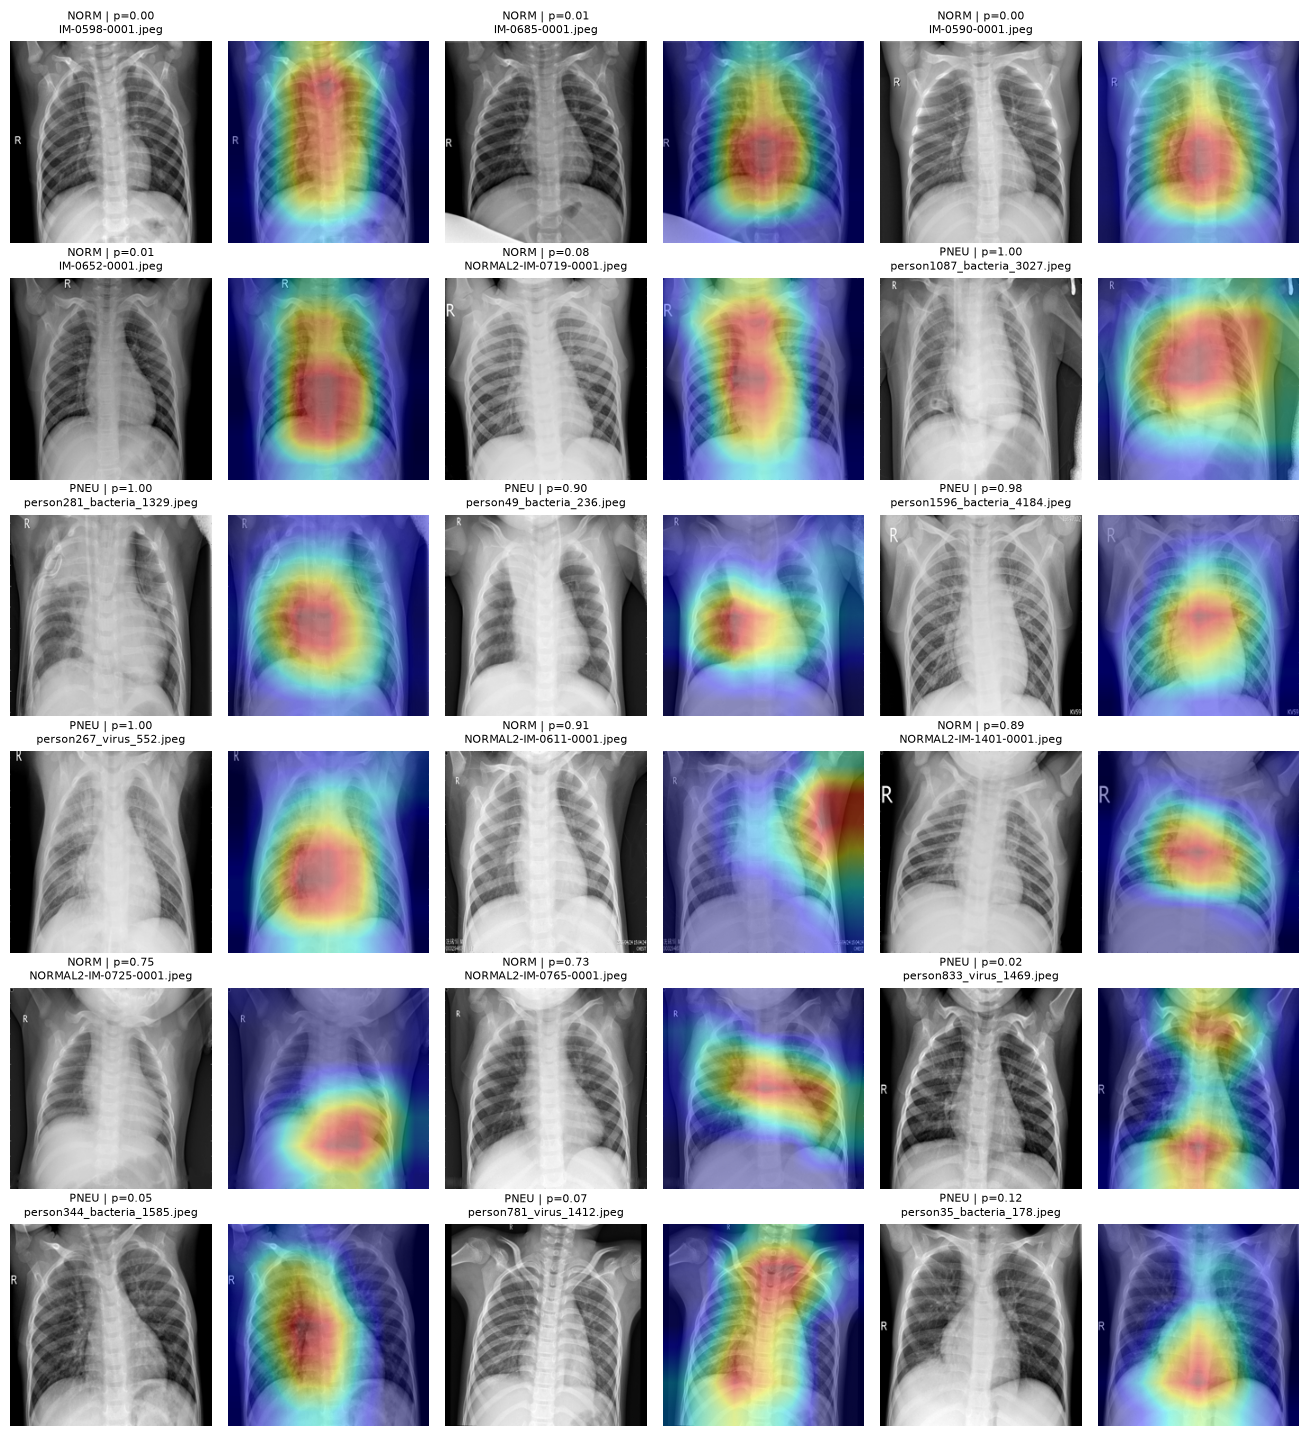

Trung bình năng lượng viền (border_mass) theo từng lớp:
label
0    0.153585
1    0.155937
Name: border_mass, dtype: float32

(Lưu ý: Nếu năng lượng rải đều toàn ảnh, viền 10% mỗi cạnh sẽ chiếm ~36% tổng năng lượng)


,label,pred,prob,border_mass
0,0,0,0.001170,0.147953
1,0,0,0.009400,0.114713
2,0,0,0.000878,0.128023
3,0,0,0.013767,0.132222
4,0,0,0.077323,0.168457
5,1,1,0.999881,0.188412
6,1,1,0.999997,0.115299
7,1,1,0.901525,0.125410
8,1,1,0.978972,0.099908
9,1,1,0.999273,0.144392


In [50]:
run_gradcam(m, sel, tfm_none,load_img, project_root/'reports/figures/gradcam_last.png', )

# 6. Choose Threshold

In [51]:

def choose_threshold(y, p, target_recall):
    fpr, tpr, thr = roc_curve(y, p)
    idx = np.where(tpr >= target_recall)[0]
    i = idx[np.argmin(fpr[idx])]                  # specificity cao nhất trong số điểm đạt recall mục tiêu
    return float(thr[i])                          # dự đoán PNEUMONIA khi prob >= ngưỡng

def load_model(name, seed=36):
    m = build_model('last')
    m.load_state_dict(torch.load(project_root/f'outputs/checkpoints/{name}_seed{seed}.pt', map_location=device))
    return m.eval()

protocol = {'primary_model': 'r18_last_aug_shortcut', 'reference_model': 'r18_last_aug_none',
            'primary_target_recall': 0.95, 'date': str(datetime.datetime.now()), 'thresholds': {}}
for name in [protocol['primary_model'], protocol['reference_model']]:
    m = load_model(name)
    pv, yv = get_probs_and_labels(m, val_dl)                    # val_dl: transform sạch, shuffle=False
    protocol['thresholds'][name] = {}
    for target in [0.95, 0.98]:
        thr = choose_threshold(yv, pv, target)
        tn, fp, fn, tp = confusion_matrix(yv, pv >= thr).ravel()
        protocol['thresholds'][name][str(target)] = {'thr': thr, 'val_recall': tp / (tp + fn), 'val_spec': tn / (tn + fp)}
        print(name, target, f'thr={thr:.4f}', f'val recall={tp/(tp+fn):.3f} spec={tn/(tn+fp):.3f}')


json.dump(protocol, open(project_root/'outputs/results/final_protocol.json', 'w'), indent=2)

r18_last_aug_shortcut 0.95 thr=0.7638 val recall=0.959 spec=0.993
r18_last_aug_shortcut 0.98 thr=0.4055 val recall=0.981 spec=0.970
r18_last_aug_none 0.95 thr=0.9987 val recall=0.954 spec=1.000
r18_last_aug_none 0.98 thr=0.6950 val recall=0.990 spec=0.996


**Pick threshold equals:**
- 0.4055 with r18_last_aug_shortcut model
- 0.6950 with r18_last_aug_none model


# 7. Test

In [52]:
TEST_CSV = project_root / 'data/data_split/test.csv'
rows = []
for lab_name, lab in [('NORMAL', 0), ('PNEUMONIA', 1)]:
    for f in sorted([f for f in (base_dir / 'test' / lab_name).iterdir() if f.suffix.lower() in ['.jpg', '.jpeg', '.png']]):
        rows.append({'path': f.relative_to(base_dir).as_posix(), 'label': lab, 'patient_id': get_patient_id(f)})
test_df = pd.DataFrame(rows); test_df.to_csv(TEST_CSV, index=False)
print(len(test_df), test_df.label.value_counts().to_dict())


624 {1: 390, 0: 234}


In [54]:
test_dl = DataLoader(CXRDataset(TEST_CSV, tfm_none, base_dir), batch_size=64, shuffle=False, num_workers=2)   # ... = các đối số bạn dùng cho val_dl

def report(y, p, thr):
    pred = p >= thr
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {'auc': roc_auc_score(y, p), 'pr_auc': average_precision_score(y, p), 'thr': thr,
            'recall': tp / (tp + fn), 'specificity': tn / (tn + fp),
            'precision': tp / (tp + fp) if tp + fp else np.nan, 'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp}

def boot_ci(y, p, thr, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    out = {'auc': [], 'recall': [], 'specificity': []}
    for _ in range(n):
        idx = np.r_[rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]
        yy, pp = y[idx], p[idx]; pred = pp >= thr
        out['auc'].append(roc_auc_score(yy, pp))
        out['recall'].append(pred[yy == 1].mean()); out['specificity'].append((~pred[yy == 0]).mean())
    return {k: np.percentile(v, [2.5, 97.5]).round(3).tolist() for k, v in out.items()}

rows = []
for name in [protocol['primary_model'], protocol['reference_model']]:
    m = load_model(name)
    pt, yt = get_probs_and_labels(m, test_dl)
    assert (yt == test_df.label.values).all()                      # thứ tự khớp test_df
    pd.DataFrame({'path': test_df.path, 'label': yt, 'prob': pt}).to_csv(project_root/f'outputs_aug/results/test_probs_{name}.csv', index=False)
    for target in ['0.95', '0.98']:
        thr = protocol['thresholds'][name][target]['thr']
        r = report(yt, pt, thr); ci = boot_ci(yt, pt, thr)
        v = protocol['thresholds'][name][target]
        rows.append({'model': name, 'target': target, **r, 'val_recall': v['val_recall'], 'val_spec': v['val_spec'], 'CI': ci})
test_table = pd.DataFrame(rows); print(test_table.round(3).to_string())
test_table.to_csv(project_root/'outputs/results/test_final.csv', index=False)

                   model target    auc  pr_auc    thr  recall  specificity  precision   tn   fp  fn   tp  val_recall  val_spec                                                                                CI
0  r18_last_aug_shortcut   0.95  0.979   0.984  0.764   0.982        0.885      0.934  207   27   7  383       0.959     0.993   {'auc': [0.967, 0.99], 'recall': [0.967, 0.995], 'specificity': [0.842, 0.923]}
1  r18_last_aug_shortcut   0.98  0.979   0.984  0.406   0.995        0.799      0.892  187   47   2  388       0.981     0.970      {'auc': [0.967, 0.99], 'recall': [0.987, 1.0], 'specificity': [0.744, 0.85]}
2      r18_last_aug_none   0.95  0.940   0.946  0.999   0.962        0.778      0.878  182   52  15  375       0.954     1.000  {'auc': [0.919, 0.959], 'recall': [0.944, 0.979], 'specificity': [0.722, 0.829]}
3      r18_last_aug_none   0.98  0.940   0.946  0.695   0.997        0.543      0.784  127  107   1  389       0.990     0.996    {'auc': [0.919, 0.959], 'recall': 